In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)

# Consistent EDA styling
sns.set_theme(style="whitegrid", context="notebook")

# Paths

In [2]:
PROJECT_DIR = Path(os.getcwd())

DATA_DIR = PROJECT_DIR/"data"

INTERIM_DIR = PROJECT_DIR / "data" / "interim"
SEMICLEANED_DIR = INTERIM_DIR / "worldbank_semicleaned_wide"

CLEAN_DIR = DATA_DIR/"clean"

INPUT_PATH = SEMICLEANED_DIR / "worldbank_un_cleaned.csv"
NON_UN_PATH = SEMICLEANED_DIR/"worldbank_non_un.csv"

REPORT_DIR = PROJECT_DIR / "reports"
IMPUTATION_DIAGNOSTICS_DIR = REPORT_DIR / "imputation_diagnostics"
IMPUTATION_DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)

print("Input:", INPUT_PATH)
print("Clean: ",CLEAN_DIR)



Input: d:\DA2402\Project\EarthQuake\data\interim\worldbank_semicleaned_wide\worldbank_un_cleaned.csv
Clean:  d:\DA2402\Project\EarthQuake\data\clean


In [3]:
for path in [INPUT_PATH, NON_UN_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

# Load both datasets
df_un = pd.read_csv(INPUT_PATH, dtype={"country_iso3": "string"})
df_non_un = pd.read_csv(NON_UN_PATH, dtype={"country_iso3": "string"})

def find_taiwan(df, dataset_name):
    # Use whichever ISO3 column exists
    iso_col = next(
        (c for c in ["country_iso3_clean", "country_iso3"]
         if c in df.columns),
        None
    )

    # Search by ISO3 code
    code_match = (
        df[iso_col].astype("string").str.strip().str.upper().eq("TWN")
        if iso_col else pd.Series(False, index=df.index)
    )

    # Also search country names in case the label differs
    name_cols = [
        c for c in ["country_name", "country", "name"]
        if c in df.columns
    ]

    name_match = pd.Series(False, index=df.index)

    for col in name_cols:
        name_match |= df[col].astype("string").str.contains(
            r"taiwan|chinese taipei",
            case=False,
            na=False,
            regex=True
        )

    matches = df.loc[code_match | name_match]

    print(f"\n{dataset_name}:")
    if matches.empty:
        print("No Taiwan-related records found.")
    else:
        display(matches.head(10))
        print("Matching rows:", len(matches))

    return matches

taiwan_in_un = find_taiwan(df_un, "UN dataset")
taiwan_in_non_un = find_taiwan(df_non_un, "Non-UN dataset")


UN dataset:
No Taiwan-related records found.

Non-UN dataset:
No Taiwan-related records found.


In [4]:
# Create the clean directory if it doesn't exist
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

# Verify that the input file exists
if not INPUT_PATH.exists():
    raise FileNotFoundError(f"Input file not found: {INPUT_PATH}")

# Load the pre-imputation dataset
df_original = pd.read_csv(INPUT_PATH)

# Create a working copy for subsequent cleaning and imputation
df_imputation = df_original.copy()

# Validate required columns
required_cols = ["country_iso3_clean", "year"]
missing_required = [
    col for col in required_cols
    if col not in df_imputation.columns
]

if missing_required:
    raise ValueError(f"Required columns are missing: {missing_required}")

# Standardise year to numeric in the working copy
df_imputation["year"] = pd.to_numeric(
    df_imputation["year"], errors="coerce"
)

print("Dataset shape:", df_imputation.shape)
print("Unique entities:", df_imputation["country_iso3_clean"].nunique())
print("Year range:", df_imputation["year"].min(), "to", df_imputation["year"].max())

print("\nData types and non-null counts:")
df_imputation.info()

# Check whether each entity-year combination is unique
duplicate_count = df_imputation.duplicated(
    subset=["country_iso3_clean", "year"]
).sum()

print("\nDuplicate country-year rows:", duplicate_count)

# Review missingness before imputation
missingness_before = pd.DataFrame({
    "missing_count": df_imputation.isna().sum(),
    "missing_percent": df_imputation.isna().mean() * 100,
    "available_count": df_imputation.notna().sum()
}).sort_values("missing_percent", ascending=False)

print("\nMissingness before imputation:")
display(missingness_before.round(2))

# Preview the data
display(df_imputation.head())

Dataset shape: (4940, 25)
Unique entities: 190
Year range: 2000 to 2025

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 4940 entries, 0 to 4939
Data columns (total 25 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   country_iso3_clean                4940 non-null   str    
 1   country_name                      4940 non-null   str    
 2   country_iso2                      4914 non-null   str    
 3   region                            4940 non-null   str    
 4   income_group                      4940 non-null   str    
 5   country_iso3                      4940 non-null   str    
 6   year                              4940 non-null   int64  
 7   gdp_current_usd                   4918 non-null   float64
 8   gdp_per_capita_current_usd        4918 non-null   float64
 9   gdp_constant_2015_usd             4909 non-null   float64
 10  gdp_per_capita_constant_2015_usd  4909

,missing_count,missing_percent,available_count
inflation_cpi_pct,398,8.06,4542
unemployment_pct,373,7.55,4567
population_density_per_sq_km,215,4.35,4725
electricity_access_pct,199,4.03,4741
life_expectancy_years,190,3.85,4750
gdp_per_capita_ppp_constant_2021,126,2.55,4814
gdp_ppp_constant_2021,126,2.55,4814
real_gdp_growth_pct,33,0.67,4907
inflation_gdp_deflator_pct,33,0.67,4907
real_gdp_per_capita_growth_pct,33,0.67,4907


,country_iso3_clean,country_name,country_iso2,region,income_group,country_iso3,year,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population_pct,rural_population_pct,electricity_access_pct,unemployment_pct,life_expectancy_years
0,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2000,3.521418e+09,174.930991,6.206548e+09,308.318270,3.256738e+10,1617.826475,NaN,NaN,NaN,NaN,20130327.0,30.863847,1.212176,18.558200,81.441802,4.4,7.897,55.005
1,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2001,2.813572e+09,138.706822,5.621148e+09,277.118051,2.949563e+10,1454.110782,-9.431974,-10.119484,NaN,-11.774536,20284307.0,31.099929,0.762005,18.741238,81.258763,9.3,7.973,55.511
2,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2002,3.825701e+09,178.954088,7.228796e+09,338.139974,3.793138e+10,1774.308743,28.600001,22.020190,NaN,6.125522,21378117.0,32.776961,5.252030,18.941248,81.058753,14.1,7.867,56.225
3,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2003,4.520947e+09,198.871116,7.867263e+09,346.071627,4.128158e+10,1815.928200,8.832278,2.345672,NaN,11.655238,22733049.0,34.854344,6.145194,19.160035,80.839966,19.0,7.844,57.171
4,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2004,5.224897e+09,221.763654,7.978516e+09,338.637274,4.186536e+10,1776.918207,1.414118,-2.148212,NaN,11.271432,23560654.0,36.123230,3.575835,19.399359,80.600640,23.8,7.794,57.810


In [5]:
# Cell 7: Compare missingness in 2000–2023 and 2024–2025

audit_df = df_original.copy()
audit_df["year"] = pd.to_numeric(audit_df["year"], errors="coerce")

# All numeric indicator columns, excluding year itself
INDICATOR_COLS = [
    col for col in audit_df.select_dtypes(include=np.number).columns
    if col != "year"
]

PERIODS = {
    "2000_2023": (2000, 2023),
    "2024_2025": (2024, 2025),
}

records = []

for period_name, (start_year, end_year) in PERIODS.items():
    period_df = audit_df.loc[
        audit_df["year"].between(start_year, end_year)
    ]

    total_cells_per_indicator = len(period_df)

    for col in INDICATOR_COLS:
        missing_count = int(period_df[col].isna().sum())

        records.append({
            "indicator": col,
            "period": period_name,
            "rows_in_period": len(period_df),
            "missing_count": missing_count,
            "available_count": total_cells_per_indicator - missing_count,
            "missing_pct": (
                100 * missing_count / total_cells_per_indicator
                if total_cells_per_indicator else np.nan
            ),
        })

period_missingness_long = pd.DataFrame(records)

# Pivot into a readable summary table
period_missingness = period_missingness_long.pivot(
    index="indicator",
    columns="period",
    values=["missing_count", "missing_pct", "available_count"],
)

# Flatten the multi-level column names
period_missingness.columns = [
    f"{metric}_{period}"
    for metric, period in period_missingness.columns
]

period_missingness = period_missingness.sort_values(
    "missing_pct_2024_2025",
    ascending=False
)

print("Missingness by period:")
display(period_missingness.round(2))

print("\nRows available in each period:")
print(
    "2000–2023:",
    audit_df["year"].between(2000, 2023).sum()
)
print(
    "2024–2025:",
    audit_df["year"].between(2024, 2025).sum()
)

Missingness by period:


,missing_count_2000_2023,missing_count_2024_2025,missing_pct_2000_2023,missing_pct_2024_2025,available_count_2000_2023,available_count_2024_2025
indicator,,,,,,
population_density_per_sq_km,24.0,191.0,0.53,50.26,4536.0,189.0
electricity_access_pct,9.0,190.0,0.20,50.00,4551.0,190.0
life_expectancy_years,0.0,190.0,0.00,50.00,4560.0,190.0
inflation_cpi_pct,356.0,42.0,7.81,11.05,4204.0,338.0
unemployment_pct,339.0,34.0,7.43,8.95,4221.0,346.0
gdp_per_capita_ppp_constant_2021,110.0,16.0,2.41,4.21,4450.0,364.0
gdp_ppp_constant_2021,110.0,16.0,2.41,4.21,4450.0,364.0
gdp_current_usd,9.0,13.0,0.20,3.42,4551.0,367.0
gdp_per_capita_current_usd,9.0,13.0,0.20,3.42,4551.0,367.0



Rows available in each period:
2000–2023: 4560
2024–2025: 380


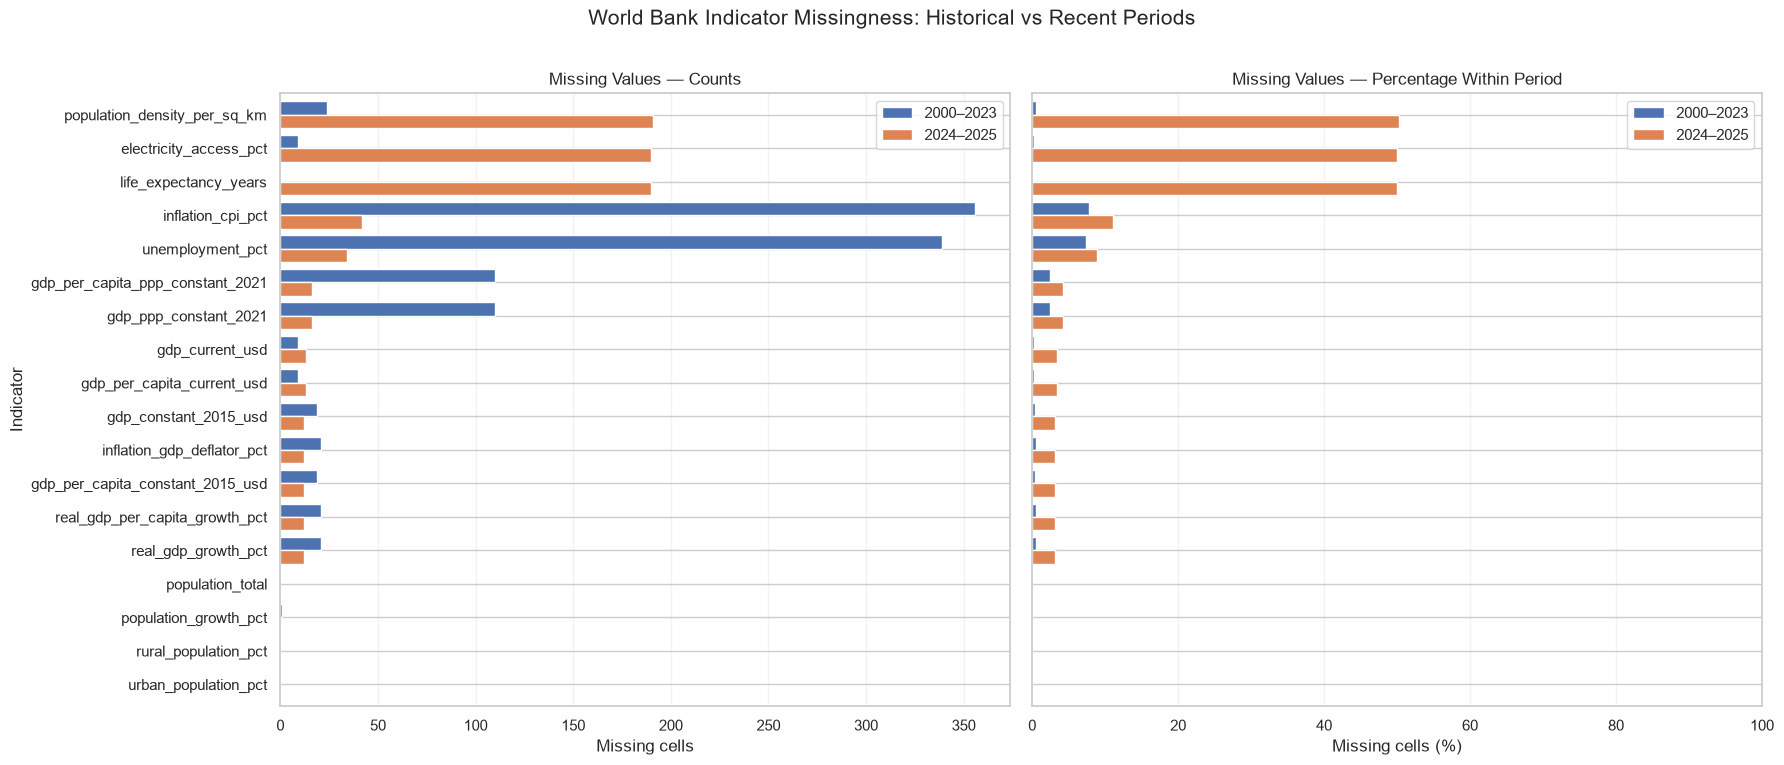

In [6]:
# Cell 8: Visual comparison of missingness by period

count_cols = [
    "missing_count_2000_2023",
    "missing_count_2024_2025",
]

pct_cols = [
    "missing_pct_2000_2023",
    "missing_pct_2024_2025",
]

plot_order = period_missingness.index

count_plot = period_missingness[count_cols].rename(columns={
    "missing_count_2000_2023": "2000–2023",
    "missing_count_2024_2025": "2024–2025",
})

pct_plot = period_missingness[pct_cols].rename(columns={
    "missing_pct_2000_2023": "2000–2023",
    "missing_pct_2024_2025": "2024–2025",
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, max(7, len(plot_order) * 0.42)),
    sharey=True,
)

count_plot.loc[plot_order].plot(
    kind="barh", ax=axes[0], width=0.8
)
axes[0].set_title("Missing Values — Counts")
axes[0].set_xlabel("Missing cells")
axes[0].set_ylabel("Indicator")
axes[0].grid(axis="x", alpha=0.25)

pct_plot.loc[plot_order].plot(
    kind="barh", ax=axes[1], width=0.8
)
axes[1].set_title("Missing Values — Percentage Within Period")
axes[1].set_xlabel("Missing cells (%)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 100)
axes[1].grid(axis="x", alpha=0.25)

# Put the highest recent-period missingness at the top
axes[0].invert_yaxis()

fig.suptitle(
    "World Bank Indicator Missingness: Historical vs Recent Periods",
    fontsize=15,
    y=1.01,
)
plt.tight_layout()
plt.show()

In [7]:
from sklearn.linear_model import LinearRegression

# Always start from the original dataset so rerunning is reproducible
df_imputation = (
    df_original.copy()
    .sort_values(["country_iso3_clean", "year"])
    .reset_index(drop=True)
)

df_imputation["year"] = pd.to_numeric(
    df_imputation["year"], errors="coerce"
)

# Identify numeric indicators, excluding year
indicator_cols = [
    col
    for col in df_imputation.select_dtypes(include=np.number).columns
    if col != "year"
]

# Ensure indicator columns contain numeric values and no infinities
for col in indicator_cols:
    df_imputation[col] = pd.to_numeric(
        df_imputation[col], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

MISSINGNESS_THRESHOLD = 0.30
R2_THRESHOLD = 0.50

# Indicators with natural value constraints
PERCENT_0_100 = {
    "electricity_access_pct",
    "urban_population_pct",
    "rural_population_pct",
    "unemployment_pct",
}

NONNEGATIVE_COLS = {
    "gdp_current_usd",
    "gdp_per_capita_current_usd",
    "gdp_constant_2015_usd",
    "gdp_per_capita_constant_2015_usd",
    "gdp_ppp_constant_2021",
    "gdp_per_capita_ppp_constant_2021",
    "population_total",
    "population_density_per_sq_km",
    "life_expectancy_years",
}

# Initialise a flag for every numeric indicator
for col in indicator_cols:
    df_imputation[f"{col}_imputed_flag"] = False

imputation_records = []

for iso3, group in df_imputation.groupby(
    "country_iso3_clean", sort=False
):
    group = group.sort_values("year")
    idx = group.index.to_numpy()

    # Use year - 2000 as the regression predictor
    years = np.array(
        group["year"].to_numpy(dtype=float),
        dtype=float,
        copy=True,
    )

    for col in indicator_cols:
        # Explicitly create a writable copy: avoids the read-only-array error
        values = np.array(
            group[col].to_numpy(dtype=float),
            dtype=float,
            copy=True,
        )

        missing_mask = ~np.isfinite(values)
        n_missing = int(missing_mask.sum())
        n_total = len(values)

        if n_missing == 0:
            continue

        missing_pct = n_missing / n_total if n_total else 1.0

        # Rule 1: skip the series when missingness is 30% or greater
        if missing_pct >= MISSINGNESS_THRESHOLD:
            imputation_records.append({
                "country_iso3": iso3,
                "indicator": col,
                "missing_pct_before": missing_pct * 100,
                "r2": np.nan,
                "method": "none",
                "values_imputed": 0,
                "missing_remaining": n_missing,
                "status": "skipped: missingness >= 30%",
            })
            continue

        observed_mask = (
            ~missing_mask
            & np.isfinite(years)
        )

        X_train = (
            years[observed_mask] - 2000
        ).reshape(-1, 1)

        y_train = values[observed_mask]

        r2 = np.nan

        # Start with a writable copy of the original series
        new_values = values.copy()

        # Rule 2: fit linear regression when enough observations exist
        if len(y_train) >= 3 and len(np.unique(X_train)) >= 2:
            model = LinearRegression()
            model.fit(X_train, y_train)

            # In-sample R², as specified by your rule
            r2 = float(model.score(X_train, y_train))

        else:
            model = None

        if model is not None and r2 >= R2_THRESHOLD:
            # Predict every missing year for this country-indicator series
            missing_positions = np.flatnonzero(
                missing_mask & np.isfinite(years)
            )

            if len(missing_positions):
                X_missing = (
                    years[missing_positions] - 2000
                ).reshape(-1, 1)

                new_values[missing_positions] = model.predict(
                    X_missing
                )

            method = "linear_regression"

        else:
            # Rule 3: if R² < 0.5, forward-fill from the last observed value.
            # Leading missing values remain missing.
            new_values = pd.Series(values).ffill().to_numpy(
                dtype=float,
                copy=True,
            )

            # Guarantee writeability before applying bounds
            new_values = np.array(
                new_values, dtype=float, copy=True
            )

            method = "forward_fill"

        # Ensure the destination is writable before changing predictions
        new_values = np.array(
            new_values, dtype=float, copy=True
        )

        # Identify which originally missing cells were actually filled
        filled_mask = (
            missing_mask
            & np.isfinite(new_values)
        )

        # Apply basic physical bounds to newly imputed values only
        if col in PERCENT_0_100:
            new_values[filled_mask] = np.clip(
                new_values[filled_mask], 0, 100
            )

        elif col in NONNEGATIVE_COLS:
            new_values[filled_mask] = np.maximum(
                new_values[filled_mask], 0
            )

        # Round imputed values to 3 decimal places; retain observed precision
        new_values[filled_mask] = np.round(
            new_values[filled_mask], 3
        )

        # Store the values and their imputation flags
        df_imputation.loc[idx, col] = new_values
        df_imputation.loc[
            idx, f"{col}_imputed_flag"
        ] = filled_mask

        imputation_records.append({
            "country_iso3": iso3,
            "indicator": col,
            "missing_pct_before": missing_pct * 100,
            "r2": r2,
            "method": method,
            "values_imputed": int(filled_mask.sum()),
            "missing_remaining": int(
                pd.isna(df_imputation.loc[idx, col]).sum()
            ),
            "status": "processed",
        })

# Detailed audit of the imputation decisions
imputation_log = pd.DataFrame(imputation_records)

print("Imputation summary by indicator and method:")

display(
    imputation_log.groupby(
        ["indicator", "method", "status"],
        dropna=False,
    ).agg(
        country_series=("country_iso3", "count"),
        values_imputed=("values_imputed", "sum"),
        missing_remaining=("missing_remaining", "sum"),
    ).reset_index()
)

print("\nTotal missing indicator cells before:")
print(int(df_original[indicator_cols].isna().sum().sum()))

print("\nTotal missing indicator cells after:")
print(int(df_imputation[indicator_cols].isna().sum().sum()))

print("\nTotal values imputed:")
print(int(imputation_log["values_imputed"].sum()))

print("\nImputation log preview:")
display(imputation_log.head(20).round(3))

Imputation summary by indicator and method:


,indicator,method,status,country_series,values_imputed,missing_remaining
0,electricity_access_pct,forward_fill,processed,23,23,0
1,electricity_access_pct,linear_regression,processed,166,168,0
2,electricity_access_pct,none,skipped: missingness >= 30%,1,0,8
3,gdp_constant_2015_usd,forward_fill,processed,5,14,0
4,gdp_constant_2015_usd,linear_regression,processed,4,4,0
5,gdp_constant_2015_usd,none,skipped: missingness >= 30%,1,0,13
6,gdp_current_usd,forward_fill,processed,3,6,0
7,gdp_current_usd,linear_regression,processed,6,16,0
8,gdp_per_capita_constant_2015_usd,forward_fill,processed,3,3,0
9,gdp_per_capita_constant_2015_usd,linear_regression,processed,6,15,0



Total missing indicator cells before:
1833

Total missing indicator cells after:
1047

Total values imputed:
786

Imputation log preview:


,country_iso3,indicator,missing_pct_before,r2,method,values_imputed,missing_remaining,status
0,AFG,gdp_current_usd,3.846,0.668,linear_regression,1,0,processed
1,AFG,gdp_per_capita_current_usd,3.846,0.335,forward_fill,1,0,processed
2,AFG,gdp_constant_2015_usd,3.846,0.694,linear_regression,1,0,processed
3,AFG,gdp_per_capita_constant_2015_usd,3.846,0.224,forward_fill,1,0,processed
4,AFG,gdp_ppp_constant_2021,3.846,0.694,linear_regression,1,0,processed
5,AFG,gdp_per_capita_ppp_constant_2021,3.846,0.224,forward_fill,1,0,processed
6,AFG,real_gdp_growth_pct,7.692,0.226,forward_fill,1,1,processed
7,AFG,real_gdp_per_capita_growth_pct,7.692,0.207,forward_fill,1,1,processed
8,AFG,inflation_cpi_pct,23.077,0.180,forward_fill,1,5,processed
9,AFG,inflation_gdp_deflator_pct,7.692,0.049,forward_fill,1,1,processed


In [8]:
# Check whether imputation changed any originally observed data

KEY_COLS = ["country_iso3_clean", "year"]

before = df_original.copy()
after = df_imputation.copy()

# Standardise join keys for a reliable comparison
for frame in [before, after]:
    frame["country_iso3_clean"] = (
        frame["country_iso3_clean"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    frame["year"] = pd.to_numeric(
        frame["year"], errors="raise"
    )

# Check uniqueness of country-year keys
assert not before.duplicated(KEY_COLS).any(), (
    "Original data contains duplicate country-year keys."
)
assert not after.duplicated(KEY_COLS).any(), (
    "Imputed data contains duplicate country-year keys."
)

# Align rows by country and year, regardless of row ordering
before = before.set_index(KEY_COLS).sort_index()
after = after.set_index(KEY_COLS).sort_index()

# Verify that no rows were added or removed
if not before.index.equals(after.index):
    missing_rows = before.index.difference(after.index)
    extra_rows = after.index.difference(before.index)

    raise ValueError(
        f"Country-year records changed. "
        f"Missing rows: {len(missing_rows)}, "
        f"extra rows: {len(extra_rows)}."
    )

# Compare every original column; ignore newly added flag columns
audit_records = []

for col in df_original.columns:
    if col in KEY_COLS:
        continue

    if col not in after.columns:
        raise ValueError(f"Original column disappeared: {col}")

    old = before[col]
    new = after[col]

    old_present = old.notna()
    new_present = new.notna()

    # Count originally observed values that became missing
    values_removed = int((old_present & ~new_present).sum())

    # Count originally missing values that were filled
    values_filled = int((~old_present & new_present).sum())

    # Check whether originally observed values changed
    both_present = old_present & new_present

    if (
        pd.api.types.is_numeric_dtype(old)
        and pd.api.types.is_numeric_dtype(new)
    ):
        old_num = pd.to_numeric(old, errors="coerce")
        new_num = pd.to_numeric(new, errors="coerce")

        changed = both_present & ~np.isclose(
            old_num.fillna(0).to_numpy(dtype=float),
            new_num.fillna(0).to_numpy(dtype=float),
            rtol=0,
            atol=1e-8,
        )

    else:
        changed = (
            both_present
            & old.astype("string").ne(new.astype("string"))
        )

    audit_records.append({
        "column": col,
        "original_non_null": int(old_present.sum()),
        "values_filled": values_filled,
        "values_removed": values_removed,
        "original_values_changed": int(changed.sum()),
    })

integrity_report = pd.DataFrame(audit_records)

display(integrity_report)

# Overall integrity summary
print("Original shape:", df_original.shape)
print("Imputed shape:", df_imputation.shape)
print("Original country-year keys:", len(before))
print("Imputed country-year keys:", len(after))

print(
    "\nTotal originally observed values changed:",
    integrity_report["original_values_changed"].sum()
)
print(
    "Total originally observed values removed:",
    integrity_report["values_removed"].sum()
)
print(
    "Total missing values filled:",
    integrity_report["values_filled"].sum()
)

# Confirm imputation flags are consistent with actual fills
flag_issues = []

for col in df_original.columns:
    flag_col = f"{col}_imputed_flag"

    if flag_col not in df_imputation.columns:
        continue

    original_missing = before[col].isna()
    current_present = after[col].notna()

    flags = (
        after[flag_col]
        .fillna(False)
        .astype(bool)
    )

    # A flag should only be true for an originally missing,
    # now populated value.
    inconsistent = flags & ~(original_missing & current_present)

    if inconsistent.any():
        flag_issues.append({
            "column": col,
            "inconsistent_flags": int(inconsistent.sum()),
        })

print("\nInconsistent imputation flags:", len(flag_issues))
if flag_issues:
    display(pd.DataFrame(flag_issues))

assert integrity_report["original_values_changed"].sum() == 0, (
    "Some originally observed values changed."
)
assert integrity_report["values_removed"].sum() == 0, (
    "Some originally observed values became missing."
)
assert not flag_issues, (
    "Some imputation flags do not correspond to actual filled values."
)

print("\nIntegrity checks passed: originally observed values are unchanged.")

,column,original_non_null,values_filled,values_removed,original_values_changed
0,country_name,4940,0,0,0
1,country_iso2,4914,0,0,0
2,region,4940,0,0,0
3,income_group,4940,0,0,0
4,country_iso3,4940,0,0,0
5,gdp_current_usd,4918,22,0,0
6,gdp_per_capita_current_usd,4918,22,0,0
7,gdp_constant_2015_usd,4909,18,0,0
8,gdp_per_capita_constant_2015_usd,4909,18,0,0
9,gdp_ppp_constant_2021,4814,9,0,0


Original shape: (4940, 25)
Imputed shape: (4940, 43)
Original country-year keys: 4940
Imputed country-year keys: 4940

Total originally observed values changed: 0
Total originally observed values removed: 0
Total missing values filled: 786

Inconsistent imputation flags: 0

Integrity checks passed: originally observed values are unchanged.


In [9]:
# Create a DataFrame with the same structure as df_un,
# but containing the imputed indicator values.

KEY_COLS = ["country_iso3_clean", "year"]

# Identify numeric indicators, excluding the year column
indicator_cols = [
    col for col in df_un.columns
    if col != "year"
    and pd.api.types.is_numeric_dtype(df_original[col])
]

# Create consistent country-year keys for alignment
def make_country_year_keys(df):
    return pd.MultiIndex.from_arrays(
        [
            df["country_iso3_clean"]
                .astype("string")
                .str.strip()
                .str.upper()
                .to_numpy(),

            pd.to_numeric(df["year"], errors="raise").to_numpy()
        ],
        names=KEY_COLS
    )

original_keys = make_country_year_keys(df_un)
imputed_keys = make_country_year_keys(df_imputation)

# Verify that country-year records are unique and match
assert original_keys.is_unique
assert imputed_keys.is_unique

assert len(original_keys) == len(imputed_keys)
assert original_keys.isin(imputed_keys).all(), (
    "Some country-year records are missing from df_imputation."
)

# Align imputed indicator values to the original df_un row order
imputed_values = df_imputation[indicator_cols].copy()
imputed_values.index = imputed_keys

aligned_values = imputed_values.reindex(original_keys)

# Create the final DataFrame
df_un_imputed = df_un.copy()

df_un_imputed.loc[:, indicator_cols] = aligned_values.to_numpy()

# Explicitly retain the original column order
df_un_imputed = df_un_imputed[df_un.columns]

# Validate the resulting structure
assert df_un_imputed.shape == df_un.shape
assert df_un_imputed.columns.equals(df_un.columns)

print("Original df_un shape:     ", df_un.shape)
print("Imputed df_un shape:      ", df_un_imputed.shape)
print("Number of columns:        ", len(df_un_imputed.columns))
print("Remaining missing indicator cells:",
      df_un_imputed[indicator_cols].isna().sum().sum())

print("\nPreview of df_un_imputed:")
display(df_un_imputed.head())

Original df_un shape:      (4940, 25)
Imputed df_un shape:       (4940, 25)
Number of columns:         25
Remaining missing indicator cells: 1047

Preview of df_un_imputed:


,country_iso3_clean,country_name,country_iso2,region,income_group,country_iso3,year,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population_pct,rural_population_pct,electricity_access_pct,unemployment_pct,life_expectancy_years
0,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2000,3.521418e+09,174.930991,6.206548e+09,308.318270,3.256738e+10,1617.826475,NaN,NaN,NaN,NaN,20130327.0,30.863847,1.212176,18.558200,81.441802,4.4,7.897,55.005
1,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2001,2.813572e+09,138.706822,5.621148e+09,277.118051,2.949563e+10,1454.110782,-9.431974,-10.119484,NaN,-11.774536,20284307.0,31.099929,0.762005,18.741238,81.258763,9.3,7.973,55.511
2,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2002,3.825701e+09,178.954088,7.228796e+09,338.139974,3.793138e+10,1774.308743,28.600001,22.020190,NaN,6.125522,21378117.0,32.776961,5.252030,18.941248,81.058753,14.1,7.867,56.225
3,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2003,4.520947e+09,198.871116,7.867263e+09,346.071627,4.128158e+10,1815.928200,8.832278,2.345672,NaN,11.655238,22733049.0,34.854344,6.145194,19.160035,80.839966,19.0,7.844,57.171
4,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2004,5.224897e+09,221.763654,7.978516e+09,338.637274,4.186536e+10,1776.918207,1.414118,-2.148212,NaN,11.271432,23560654.0,36.123230,3.575835,19.399359,80.600640,23.8,7.794,57.810


In [10]:
df_un_imputed.dtypes

country_iso3_clean                      str
country_name                            str
country_iso2                            str
region                                  str
income_group                            str
country_iso3                         string
year                                  int64
gdp_current_usd                     float64
gdp_per_capita_current_usd          float64
gdp_constant_2015_usd               float64
gdp_per_capita_constant_2015_usd    float64
gdp_ppp_constant_2021               float64
gdp_per_capita_ppp_constant_2021    float64
real_gdp_growth_pct                 float64
real_gdp_per_capita_growth_pct      float64
inflation_cpi_pct                   float64
inflation_gdp_deflator_pct          float64
population_total                    float64
population_density_per_sq_km        float64
population_growth_pct               float64
urban_population_pct                float64
rural_population_pct                float64
electricity_access_pct          

In [11]:
df_un_imputed.info()

<class 'pandas.DataFrame'>
RangeIndex: 4940 entries, 0 to 4939
Data columns (total 25 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   country_iso3_clean                4940 non-null   str    
 1   country_name                      4940 non-null   str    
 2   country_iso2                      4914 non-null   str    
 3   region                            4940 non-null   str    
 4   income_group                      4940 non-null   str    
 5   country_iso3                      4940 non-null   string 
 6   year                              4940 non-null   int64  
 7   gdp_current_usd                   4940 non-null   float64
 8   gdp_per_capita_current_usd        4940 non-null   float64
 9   gdp_constant_2015_usd             4927 non-null   float64
 10  gdp_per_capita_constant_2015_usd  4927 non-null   float64
 11  gdp_ppp_constant_2021             4823 non-null   float64
 12  gdp_per_capita_pp

In [12]:
df_un.info()

<class 'pandas.DataFrame'>
RangeIndex: 4940 entries, 0 to 4939
Data columns (total 25 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   country_iso3_clean                4940 non-null   str    
 1   country_name                      4940 non-null   str    
 2   country_iso2                      4914 non-null   str    
 3   region                            4940 non-null   str    
 4   income_group                      4940 non-null   str    
 5   country_iso3                      4940 non-null   string 
 6   year                              4940 non-null   int64  
 7   gdp_current_usd                   4918 non-null   float64
 8   gdp_per_capita_current_usd        4918 non-null   float64
 9   gdp_constant_2015_usd             4909 non-null   float64
 10  gdp_per_capita_constant_2015_usd  4909 non-null   float64
 11  gdp_ppp_constant_2021             4814 non-null   float64
 12  gdp_per_capita_pp

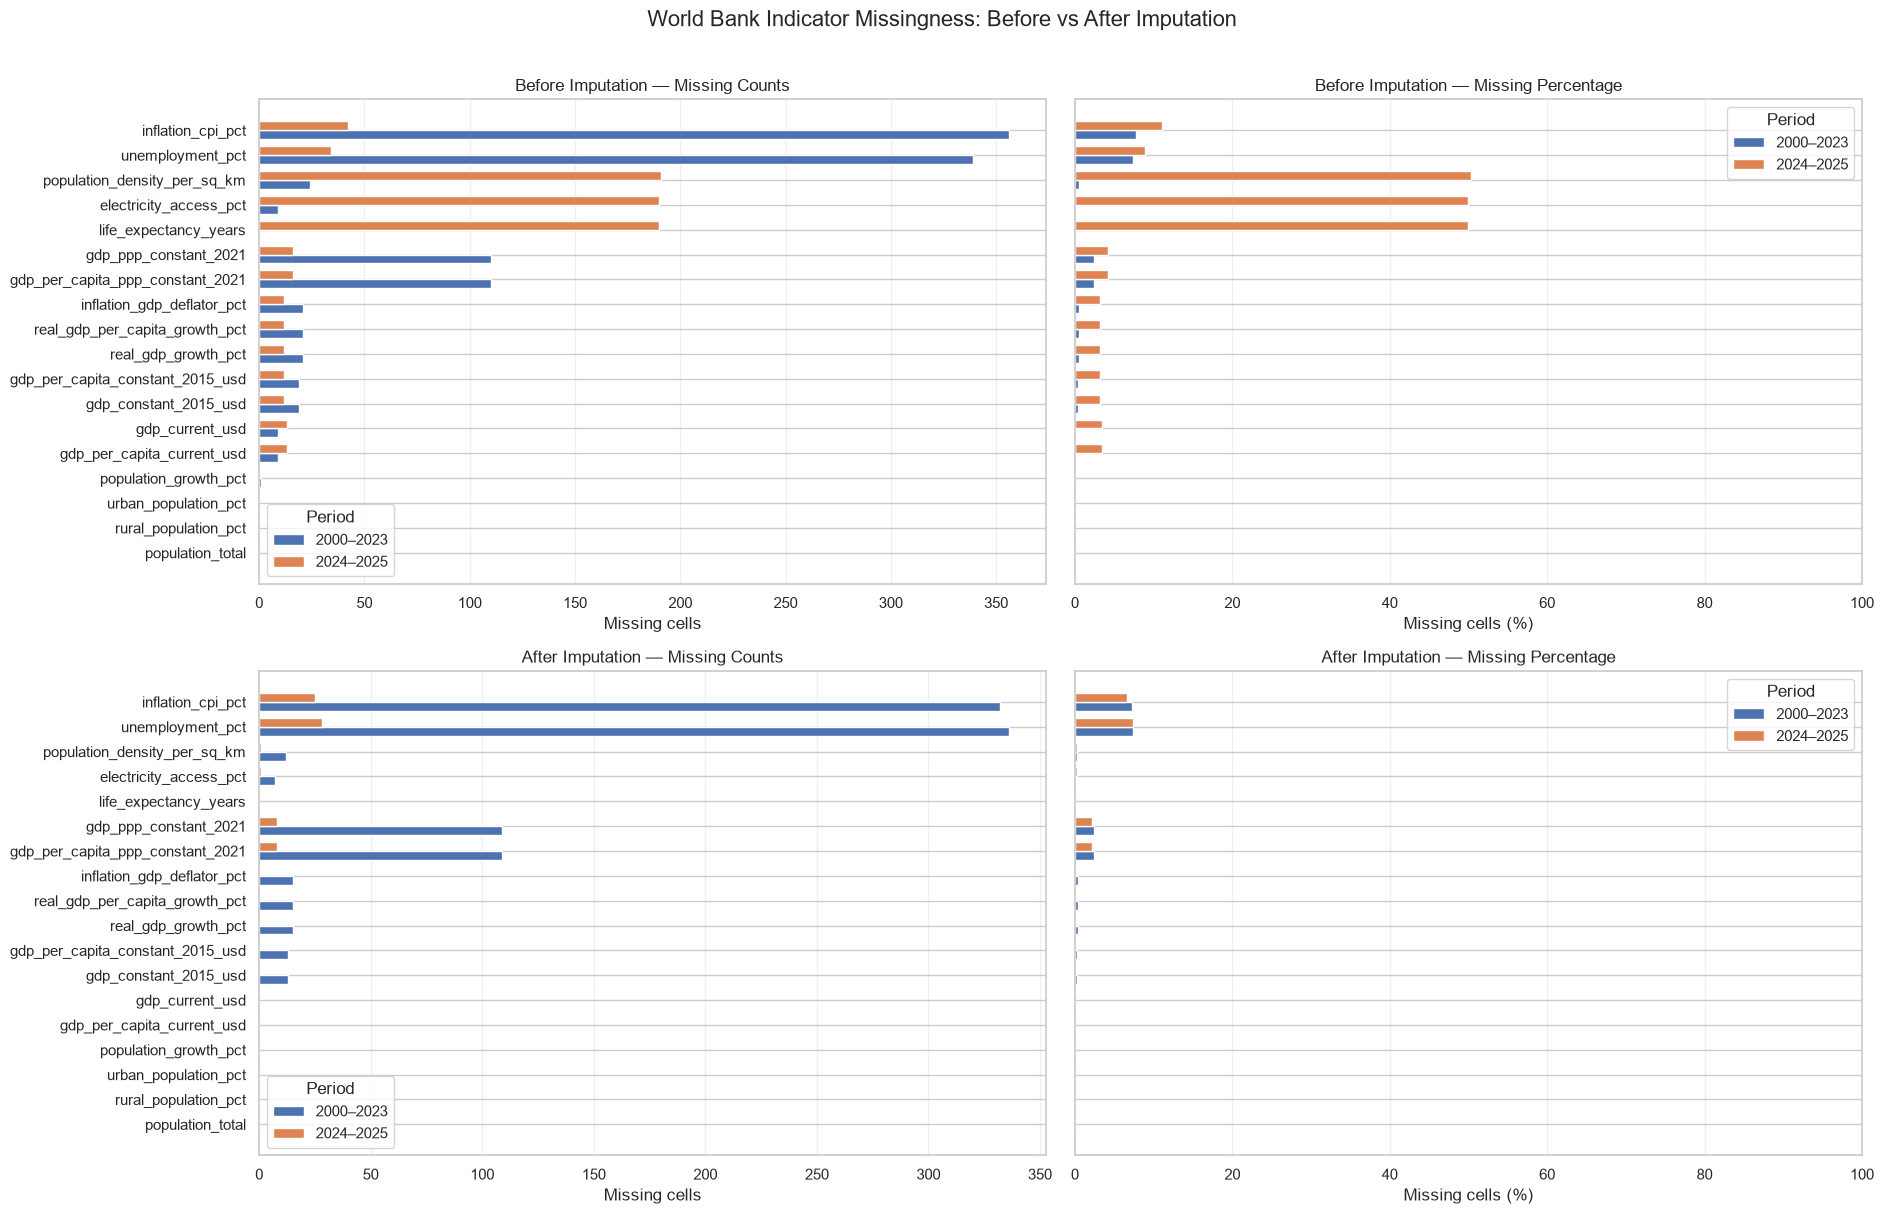

In [13]:

# Compare missingness before and after imputation
# across historical (2000–2023) and recent (2024–2025) periods

before_df = df_un.copy()
after_df = df_un_imputed.copy()

# Identify numeric indicator columns
indicator_cols = [
    col for col in before_df.select_dtypes(include=np.number).columns
    if col != "year"
]

# Standardise year
before_df["year"] = pd.to_numeric(before_df["year"])
after_df["year"] = pd.to_numeric(after_df["year"])

periods = {
    "2000–2023": (2000, 2023),
    "2024–2025": (2024, 2025)
}

def get_period_missingness(df):
    records = []

    for period_name, (start_year, end_year) in periods.items():
        period_df = df[df["year"].between(start_year, end_year)]

        for col in indicator_cols:
            missing_count = period_df[col].isna().sum()
            total_observations = len(period_df)

            missing_pct = (
                missing_count / total_observations * 100
                if total_observations > 0 else np.nan
            )

            records.append({
                "indicator": col,
                "period": period_name,
                "missing_count": missing_count,
                "missing_pct": missing_pct
            })

    return pd.DataFrame(records)


# Calculate missingness
before_missingness = get_period_missingness(before_df)
after_missingness = get_period_missingness(after_df)

# Keep the same indicator ordering in all four plots
indicator_order = (
    before_missingness
    .groupby("indicator")["missing_count"]
    .sum()
    .sort_values(ascending=True)
    .index.tolist()
)

# Plotting function
def plot_missingness(ax, data, metric, title, show_legend=True):
    bar_height = 0.36
    y = np.arange(len(indicator_order))

    for i, (period_name, _) in enumerate(periods.items()):
        values = (
            data[data["period"] == period_name]
            .set_index("indicator")[metric]
            .reindex(indicator_order)
        )

        offset = (i - 0.5) * bar_height

        ax.barh(
            y + offset,
            values,
            height=bar_height,
            label=period_name
        )

    ax.set_yticks(y)
    ax.set_yticklabels(indicator_order)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(
        "Missing cells" if metric == "missing_count"
        else "Missing cells (%)"
    )
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

    if metric == "missing_pct":
        ax.set_xlim(0, 100)

    if show_legend:
        ax.legend(title="Period")


# Create 2x2 figure
fig, axes = plt.subplots(
    2, 2,
    figsize=(19, 12),
    sharey=True
)

# Before imputation
plot_missingness(
    axes[0, 0],
    before_missingness,
    "missing_count",
    "Before Imputation — Missing Counts"
)

plot_missingness(
    axes[0, 1],
    before_missingness,
    "missing_pct",
    "Before Imputation — Missing Percentage"
)

# After imputation
plot_missingness(
    axes[1, 0],
    after_missingness,
    "missing_count",
    "After Imputation — Missing Counts"
)

plot_missingness(
    axes[1, 1],
    after_missingness,
    "missing_pct",
    "After Imputation — Missing Percentage"
)

fig.suptitle(
    "World Bank Indicator Missingness: Before vs After Imputation",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()


### As We can see We have reduce recent years missingness due to delayed information update by a ombination of linear regression with forward filling for those which got poor r2 score

In [14]:

# Post-imputation missingness report

# Use the final DataFrame with the same structure as df_un
report_df = df_un_imputed.copy()

# Identify numeric indicators, excluding year
report_indicator_cols = [
    col
    for col in report_df.select_dtypes(include=np.number).columns
    if col != "year"
]

# Calculate missingness for every indicator
null_report = pd.DataFrame({
    "indicator": report_indicator_cols,
    "total_observations": len(report_df),
    "null_count": [
        report_df[col].isna().sum()
        for col in report_indicator_cols
    ],
    "null_pct": [
        report_df[col].isna().mean() * 100
        for col in report_indicator_cols
    ],
    "non_null_count": [
        report_df[col].notna().sum()
        for col in report_indicator_cols
    ],
    "non_null_pct": [
        report_df[col].notna().mean() * 100
        for col in report_indicator_cols
    ],
})

# Sort indicators by highest remaining missingness
null_report = (
    null_report
    .sort_values("null_pct", ascending=False)
    .reset_index(drop=True)
)

# Create reports directory
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Export report
NULL_REPORT_PATH = IMPUTATION_DIAGNOSTICS_DIR / "imputation_null_pct.csv"

null_report.to_csv(
    NULL_REPORT_PATH,
    index=False,
    float_format="%.4f"
)

# Display report
display(null_report.round(3))

print("\nPost-imputation missingness summary")
print("-----------------------------------")
print("Dataset shape:", report_df.shape)
print("Indicators analysed:", len(report_indicator_cols))
print("Total missing indicator cells:", null_report["null_count"].sum())
print("Overall missingness (%):",
      round(
          null_report["null_count"].sum()
          / (len(report_df) * len(report_indicator_cols)) * 100,
          3
      ))

print("\nReport saved to:", NULL_REPORT_PATH)


,indicator,total_observations,null_count,null_pct,non_null_count,non_null_pct
0,unemployment_pct,4940,364,7.368,4576,92.632
1,inflation_cpi_pct,4940,357,7.227,4583,92.773
2,gdp_ppp_constant_2021,4940,117,2.368,4823,97.632
3,gdp_per_capita_ppp_constant_2021,4940,117,2.368,4823,97.632
4,real_gdp_per_capita_growth_pct,4940,15,0.304,4925,99.696
5,inflation_gdp_deflator_pct,4940,15,0.304,4925,99.696
6,real_gdp_growth_pct,4940,15,0.304,4925,99.696
7,population_density_per_sq_km,4940,13,0.263,4927,99.737
8,gdp_per_capita_constant_2015_usd,4940,13,0.263,4927,99.737
9,gdp_constant_2015_usd,4940,13,0.263,4927,99.737



Post-imputation missingness summary
-----------------------------------
Dataset shape: (4940, 25)
Indicators analysed: 18
Total missing indicator cells: 1047
Overall missingness (%): 1.177

Report saved to: d:\DA2402\Project\EarthQuake\reports\imputation_diagnostics\imputation_null_pct.csv


In [15]:

# Country-wise indicator missingness after imputation

analysis_df = df_un_imputed.copy()

analysis_df["year"] = pd.to_numeric(
    analysis_df["year"], errors="raise"
)

# Identify numeric indicators, excluding year
indicator_cols = [
    col
    for col in analysis_df.select_dtypes(include=np.number).columns
    if col != "year"
]

# Ensure one row per country-year
assert not analysis_df.duplicated(
    ["country_iso3_clean", "year"]
).any(), "Duplicate country-year records found."

records = []

for iso3, group in analysis_df.groupby(
    "country_iso3_clean", sort=True
):
    group = group.sort_values("year")

    country_name = (
        group["country_name"].dropna().iloc[0]
        if "country_name" in group.columns
        and group["country_name"].notna().any()
        else iso3
    )

    total_years = len(group)

    for col in indicator_cols:
        missing_mask = group[col].isna()
        missing_count = int(missing_mask.sum())
        missing_pct = (
            missing_count / total_years * 100
            if total_years else np.nan
        )

        if missing_count == 0:
            continue

        missing_years = group.loc[
            missing_mask, "year"
        ].astype(int).tolist()

        observed_years = group.loc[
            ~missing_mask, "year"
        ]

        if missing_pct == 100:
            category = "completely_missing"
        elif missing_pct >= 50:
            category = "mostly_missing"
        elif missing_pct >= 30:
            category = "high_missingness"
        else:
            category = "low_missingness"

        records.append({
            "country_iso3": iso3,
            "country_name": country_name,
            "indicator": col,
            "total_years": total_years,
            "missing_count": missing_count,
            "missing_pct": missing_pct,
            "available_count": total_years - missing_count,
            "missing_years": ", ".join(
                map(str, missing_years)
            ),
            "first_observed_year": (
                int(observed_years.min())
                if not observed_years.empty else np.nan
            ),
            "last_observed_year": (
                int(observed_years.max())
                if not observed_years.empty else np.nan
            ),
            "category": category,
        })

country_indicator_missingness = pd.DataFrame(records)

# Sort: completely missing first, then highest missingness
category_order = {
    "completely_missing": 0,
    "mostly_missing": 1,
    "high_missingness": 2,
    "low_missingness": 3,
}

country_indicator_missingness["_sort"] = (
    country_indicator_missingness["category"]
    .map(category_order)
)

country_indicator_missingness = (
    country_indicator_missingness
    .sort_values(
        ["_sort", "missing_pct", "country_name", "indicator"],
        ascending=[True, False, True, True]
    )
    .drop(columns="_sort")
    .reset_index(drop=True)
)

# Focus on country-indicator combinations with >=30% missingness
manual_candidates = country_indicator_missingness.loc[
    country_indicator_missingness["missing_pct"] >= 30
].copy()

# Summary by category
print("COUNTRY-INDICATOR MISSINGNESS SUMMARY")
print("-------------------------------------")
print("Countries analysed:", analysis_df["country_iso3_clean"].nunique())
print("Indicators analysed:", len(indicator_cols))
print("Country-indicator combinations with missing values:",
      len(country_indicator_missingness))

print("\nMissingness categories:")
display(
    country_indicator_missingness["category"]
    .value_counts()
    .rename_axis("category")
    .to_frame("country_indicator_combinations")
)

print("\nCOMPLETELY MISSING SERIES")
display(
    country_indicator_missingness.loc[
        country_indicator_missingness["category"]
        == "completely_missing"
    ].reset_index(drop=True)
)

print("\nMOSTLY / HIGHLY MISSING SERIES (>=30%)")
display(manual_candidates)

# Summarise affected countries
country_review_summary = (
    manual_candidates.groupby(
        ["country_iso3", "country_name"]
    )
    .agg(
        indicators_to_review=("indicator", "count"),
        total_missing_cells=("missing_count", "sum"),
        worst_missing_pct=("missing_pct", "max"),
        indicators=("indicator", lambda x: ", ".join(x))
    )
    .sort_values(
        ["indicators_to_review", "total_missing_cells"],
        ascending=False
    )
    .reset_index()
)

print("\nCOUNTRIES REQUIRING REVIEW")
display(country_review_summary)





COUNTRY-INDICATOR MISSINGNESS SUMMARY
-------------------------------------
Countries analysed: 190
Indicators analysed: 18
Country-indicator combinations with missing values: 65

Missingness categories:


,country_indicator_combinations
category,
completely_missing,28
low_missingness,18
mostly_missing,13
high_missingness,6



COMPLETELY MISSING SERIES


,country_iso3,country_name,indicator,total_years,missing_count,missing_pct,available_count,missing_years,first_observed_year,last_observed_year,category
0,AND,Andorra,inflation_cpi_pct,26,26,100.0,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
1,AND,Andorra,unemployment_pct,26,26,100.0,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
2,ATG,Antigua and Barbuda,unemployment_pct,26,26,100.0,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
3,CUB,Cuba,gdp_per_capita_ppp_constant_2021,26,26,100.0,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
4,CUB,Cuba,gdp_ppp_constant_2021,26,26,100.0,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
5,CUB,Cuba,inflation_cpi_pct,26,26,100.0,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
6,DMA,Dominica,unemployment_pct,26,26,100.0,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
7,GRD,Grenada,unemployment_pct,26,26,100.0,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
8,KIR,Kiribati,unemployment_pct,26,26,100.0,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
9,MHL,Marshall Islands,inflation_cpi_pct,26,26,100.0,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing



MOSTLY / HIGHLY MISSING SERIES (>=30%)


,country_iso3,country_name,indicator,total_years,missing_count,missing_pct,available_count,missing_years,first_observed_year,last_observed_year,category
0,AND,Andorra,inflation_cpi_pct,26,26,100.000000,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
1,AND,Andorra,unemployment_pct,26,26,100.000000,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
2,ATG,Antigua and Barbuda,unemployment_pct,26,26,100.000000,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
3,CUB,Cuba,gdp_per_capita_ppp_constant_2021,26,26,100.000000,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
4,CUB,Cuba,gdp_ppp_constant_2021,26,26,100.000000,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
5,CUB,Cuba,inflation_cpi_pct,26,26,100.000000,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
6,DMA,Dominica,unemployment_pct,26,26,100.000000,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
7,GRD,Grenada,unemployment_pct,26,26,100.000000,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
8,KIR,Kiribati,unemployment_pct,26,26,100.000000,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing
9,MHL,Marshall Islands,inflation_cpi_pct,26,26,100.000000,0,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007...",NaN,NaN,completely_missing



COUNTRIES REQUIRING REVIEW


,country_iso3,country_name,indicators_to_review,total_missing_cells,worst_missing_pct,indicators
0,DJI,Djibouti,7,94,53.846154,"inflation_gdp_deflator_pct, real_gdp_growth_pc..."
1,MCO,Monaco,4,104,100.000000,"gdp_per_capita_ppp_constant_2021, gdp_ppp_cons..."
2,CUB,Cuba,3,78,100.000000,"gdp_per_capita_ppp_constant_2021, gdp_ppp_cons..."
3,VEN,"Venezuela, RB",3,70,100.000000,"gdp_per_capita_ppp_constant_2021, gdp_ppp_cons..."
4,YEM,"Yemen, Rep.",3,63,100.000000,"gdp_per_capita_ppp_constant_2021, gdp_ppp_cons..."
5,AND,Andorra,2,52,100.000000,"inflation_cpi_pct, unemployment_pct"
6,MHL,Marshall Islands,2,52,100.000000,"inflation_cpi_pct, unemployment_pct"
7,TUV,Tuvalu,2,51,100.000000,"unemployment_pct, inflation_cpi_pct"
8,NRU,Naoero,2,50,100.000000,"unemployment_pct, inflation_cpi_pct"
9,ATG,Antigua and Barbuda,1,26,100.000000,unemployment_pct


In [16]:
# Create imputation diagnostics directory
IMPUTATION_DIAGNOSTICS_DIR = REPORT_DIR / "imputation_diagnostics"
IMPUTATION_DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)

# Export diagnostic reports
country_indicator_missingness.to_csv(
    IMPUTATION_DIAGNOSTICS_DIR / "country_indicator_missingness_after_imputation.csv",
    index=False
)

manual_candidates.to_csv(
    IMPUTATION_DIAGNOSTICS_DIR / "manual_imputation_candidates.csv",
    index=False
)

country_review_summary.to_csv(
    IMPUTATION_DIAGNOSTICS_DIR / "countries_requiring_manual_review.csv",
    index=False
)

print("\nDiagnostic reports saved in:")
print(IMPUTATION_DIAGNOSTICS_DIR)


Diagnostic reports saved in:
d:\DA2402\Project\EarthQuake\reports\imputation_diagnostics


In [17]:
df_un_imputed.head()

,country_iso3_clean,country_name,country_iso2,region,income_group,country_iso3,year,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population_pct,rural_population_pct,electricity_access_pct,unemployment_pct,life_expectancy_years
0,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2000,3.521418e+09,174.930991,6.206548e+09,308.318270,3.256738e+10,1617.826475,NaN,NaN,NaN,NaN,20130327.0,30.863847,1.212176,18.558200,81.441802,4.4,7.897,55.005
1,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2001,2.813572e+09,138.706822,5.621148e+09,277.118051,2.949563e+10,1454.110782,-9.431974,-10.119484,NaN,-11.774536,20284307.0,31.099929,0.762005,18.741238,81.258763,9.3,7.973,55.511
2,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2002,3.825701e+09,178.954088,7.228796e+09,338.139974,3.793138e+10,1774.308743,28.600001,22.020190,NaN,6.125522,21378117.0,32.776961,5.252030,18.941248,81.058753,14.1,7.867,56.225
3,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2003,4.520947e+09,198.871116,7.867263e+09,346.071627,4.128158e+10,1815.928200,8.832278,2.345672,NaN,11.655238,22733049.0,34.854344,6.145194,19.160035,80.839966,19.0,7.844,57.171
4,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2004,5.224897e+09,221.763654,7.978516e+09,338.637274,4.186536e+10,1776.918207,1.414118,-2.148212,NaN,11.271432,23560654.0,36.123230,3.575835,19.399359,80.600640,23.8,7.794,57.810


In [18]:

# Impute Sudan's missing population density in place

SUDAN_AREA_KM2 = 1_886_068

sudan_mask = (
    df_un_imputed["country_iso3_clean"] == "SDN"
)

missing_mask = (
    sudan_mask
    & df_un_imputed["population_density_per_sq_km"].isna()
)

# Ensure population is available for every missing observation
assert df_un_imputed.loc[
    missing_mask, "population_total"
].notna().all()

# Calculate and fill missing density values
df_un_imputed.loc[
    missing_mask, "population_density_per_sq_km"
] = (
    df_un_imputed.loc[missing_mask, "population_total"]
    / SUDAN_AREA_KM2
).round(3)

print("Sudan density values imputed:", missing_mask.sum())

display(
    df_un_imputed.loc[
        sudan_mask,
        ["country_name", "year", "population_total",
         "population_density_per_sq_km"]
    ].sort_values("year")
)


Sudan density values imputed: 13


,country_name,year,population_total,population_density_per_sq_km
3822,Sudan,2000,27816745.0,14.749000
3823,Sudan,2001,28516770.0,15.120000
3824,Sudan,2002,29228727.0,15.497000
3825,Sudan,2003,29896035.0,15.851000
3826,Sudan,2004,30556637.0,16.201000
3827,Sudan,2005,31262444.0,16.575000
3828,Sudan,2006,31992435.0,16.963000
3829,Sudan,2007,32764135.0,17.372000
3830,Sudan,2008,33623980.0,17.828000
3831,Sudan,2009,34569113.0,18.329000


In [19]:
# Round all numeric columns to 3 decimal places in place

numeric_cols = df_un_imputed.select_dtypes(
    include=np.number
).columns

df_un_imputed[numeric_cols] = (
    df_un_imputed[numeric_cols].round(3)
)

print("Rounded numeric columns:", len(numeric_cols))
print("DataFrame shape:", df_un_imputed.shape)

display(df_un_imputed.head())

Rounded numeric columns: 19
DataFrame shape: (4940, 25)


,country_iso3_clean,country_name,country_iso2,region,income_group,country_iso3,year,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population_pct,rural_population_pct,electricity_access_pct,unemployment_pct,life_expectancy_years
0,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2000,3.521418e+09,174.931,6.206548e+09,308.318,3.256738e+10,1617.826,NaN,NaN,NaN,NaN,20130327.0,30.864,1.212,18.558,81.442,4.4,7.897,55.005
1,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2001,2.813572e+09,138.707,5.621148e+09,277.118,2.949563e+10,1454.111,-9.432,-10.119,NaN,-11.775,20284307.0,31.100,0.762,18.741,81.259,9.3,7.973,55.511
2,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2002,3.825701e+09,178.954,7.228796e+09,338.140,3.793138e+10,1774.309,28.600,22.020,NaN,6.126,21378117.0,32.777,5.252,18.941,81.059,14.1,7.867,56.225
3,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2003,4.520947e+09,198.871,7.867263e+09,346.072,4.128158e+10,1815.928,8.832,2.346,NaN,11.655,22733049.0,34.854,6.145,19.160,80.840,19.0,7.844,57.171
4,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,AFG,2004,5.224897e+09,221.764,7.978516e+09,338.637,4.186536e+10,1776.918,1.414,-2.148,NaN,11.271,23560654.0,36.123,3.576,19.399,80.601,23.8,7.794,57.810


In [20]:
print(df_un_imputed.describe())
print()
print(df_un_imputed.info())

              year  gdp_current_usd  gdp_per_capita_current_usd  gdp_constant_2015_usd  gdp_per_capita_constant_2015_usd  \
count  4940.000000     4.940000e+03                 4940.000000           4.927000e+03                       4927.000000   
mean   2012.500000     3.770455e+11                13893.034968           3.740883e+11                      13700.898184   
std       7.500759     1.679263e+12                22713.293359           1.617932e+12                      21169.127631   
min    2000.000000     1.413971e+07                  109.594000           2.869155e+07                        233.032000   
25%    2006.000000     5.731239e+09                 1435.290000           6.987025e+09                       1681.831000   
50%    2012.500000     2.503985e+10                 4711.375500           2.869505e+10                       5058.646000   
75%    2019.000000     1.702033e+11                16001.218750           1.821991e+11                      16427.394000   
max    2

<class 'pandas.DataFrame'>
RangeIndex: 4940 entries, 0 to 4939
Data columns (total 25 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   country_iso3_clean                4940 non-null   str    
 1   country_name                      4940 non-null   str    
 2   country_iso2                      4914 non-null   str    
 3   region                            4940 non-null   str    
 4   income_group                      4940 non-null   str    
 5   country_iso3                      4940 non-null   string 
 6   year                              4940 non-null   int64  
 7   gdp_current_usd                   4940 non-null   float64
 8   gdp_per_capita_current_usd        4940 non-null   float64
 9   gdp_constant_2015_usd             4927 non-null   float64
 10  gdp_per_capita_constant_2015_usd  4927 non-null   float64
 11  gdp_ppp_constant_2021             4823 non-null   float64
 12  gdp_per_capita_pp

### Certain Countires Like Monaco don't have an established data an its workforce is contirbuted by workers from Italy and France. Since the data is not available frm a reliable source monaco missngness might be left like that coupling with the fact that there were no major earthquakes

In [21]:
df_un_imputed=df_un_imputed.drop(columns=['country_iso3','rural_population_pct'],errors='ignore')
df_un_imputed

,country_iso3_clean,country_name,country_iso2,region,income_group,year,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population_pct,electricity_access_pct,unemployment_pct,life_expectancy_years
0,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2000,3.521418e+09,174.931,6.206548e+09,308.318,3.256738e+10,1617.826,NaN,NaN,NaN,NaN,20130327.0,30.864,1.212,18.558,4.400,7.897,55.005
1,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2001,2.813572e+09,138.707,5.621148e+09,277.118,2.949563e+10,1454.111,-9.432,-10.119,NaN,-11.775,20284307.0,31.100,0.762,18.741,9.300,7.973,55.511
2,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2002,3.825701e+09,178.954,7.228796e+09,338.140,3.793138e+10,1774.309,28.600,22.020,NaN,6.126,21378117.0,32.777,5.252,18.941,14.100,7.867,56.225
3,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2003,4.520947e+09,198.871,7.867263e+09,346.072,4.128158e+10,1815.928,8.832,2.346,NaN,11.655,22733049.0,34.854,6.145,19.160,19.000,7.844,57.171
4,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2004,5.224897e+09,221.764,7.978516e+09,338.637,4.186536e+10,1776.918,1.414,-2.148,NaN,11.271,23560654.0,36.123,3.576,19.399,23.800,7.794,57.810
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4935,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,Lower middle income,2021,4.128785e+10,2613.617,2.072910e+10,1312.200,7.625486e+10,4827.110,8.468,6.612,98.546,108.773,15797210.0,40.835,1.726,37.869,49.000,9.540,60.135
4936,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,Lower middle income,2022,4.075759e+10,2536.402,2.200171e+10,1369.198,8.093635e+10,5036.783,6.139,4.344,104.705,274.458,16069056.0,41.538,1.706,38.706,50.100,10.087,62.360
4937,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,Lower middle income,2023,3.587178e+10,2195.225,2.317900e+10,1418.472,8.526715e+10,5218.045,5.351,3.599,NaN,768.477,16340822.0,42.241,1.677,39.292,62.000,9.348,62.775
4938,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,Lower middle income,2024,4.152198e+10,2496.155,2.356759e+10,1416.801,8.669665e+10,5211.898,1.676,-0.118,NaN,1097.520,16634373.0,43.000,1.780,39.893,62.000,9.435,63.064


In [24]:
# Verify income_group is preserved in df_un_imputed

assert "income_group" in df_un_imputed.columns, (
    "income_group is missing. Check the input CSV."
)

print("Income group successfully retained.")

display(
    df_un_imputed[
        ["country_name", "income_group"]
    ]
    .drop_duplicates()
    .head(20)
)

print("\nIncome group distribution:")
display(
    df_un_imputed["income_group"].value_counts(dropna=False)
)

Income group successfully retained.


,country_name,income_group
0,Afghanistan,Low income
26,Angola,Lower middle income
52,Albania,Upper middle income
78,Andorra,High income
104,United Arab Emirates,High income
130,Argentina,Upper middle income
156,Armenia,Upper middle income
182,Antigua and Barbuda,High income
208,Australia,High income
234,Austria,High income



Income group distribution:


income_group
High income            1664
Upper middle income    1508
Lower middle income    1196
Low income              572
Name: count, dtype: int64

In [29]:
df_un_imputed = df_un_imputed.drop(columns=['inflation_cpi_pct','unemployment_pct'],errors='ignore')
df_un_imputed

,country_iso3_clean,country_name,country_iso2,region,income_group,year,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population_pct,electricity_access_pct,life_expectancy_years
0,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2000,3.521418e+09,174.931,6.206548e+09,308.318,3.256738e+10,1617.826,NaN,NaN,NaN,20130327.0,30.864,1.212,18.558,4.400,55.005
1,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2001,2.813572e+09,138.707,5.621148e+09,277.118,2.949563e+10,1454.111,-9.432,-10.119,-11.775,20284307.0,31.100,0.762,18.741,9.300,55.511
2,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2002,3.825701e+09,178.954,7.228796e+09,338.140,3.793138e+10,1774.309,28.600,22.020,6.126,21378117.0,32.777,5.252,18.941,14.100,56.225
3,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2003,4.520947e+09,198.871,7.867263e+09,346.072,4.128158e+10,1815.928,8.832,2.346,11.655,22733049.0,34.854,6.145,19.160,19.000,57.171
4,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2004,5.224897e+09,221.764,7.978516e+09,338.637,4.186536e+10,1776.918,1.414,-2.148,11.271,23560654.0,36.123,3.576,19.399,23.800,57.810
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4935,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,Lower middle income,2021,4.128785e+10,2613.617,2.072910e+10,1312.200,7.625486e+10,4827.110,8.468,6.612,108.773,15797210.0,40.835,1.726,37.869,49.000,60.135
4936,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,Lower middle income,2022,4.075759e+10,2536.402,2.200171e+10,1369.198,8.093635e+10,5036.783,6.139,4.344,274.458,16069056.0,41.538,1.706,38.706,50.100,62.360
4937,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,Lower middle income,2023,3.587178e+10,2195.225,2.317900e+10,1418.472,8.526715e+10,5218.045,5.351,3.599,768.477,16340822.0,42.241,1.677,39.292,62.000,62.775
4938,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,Lower middle income,2024,4.152198e+10,2496.155,2.356759e+10,1416.801,8.669665e+10,5211.898,1.676,-0.118,1097.520,16634373.0,43.000,1.780,39.893,62.000,63.064


In [30]:
df_un_imputed.info()

<class 'pandas.DataFrame'>
RangeIndex: 4940 entries, 0 to 4939
Data columns (total 21 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   country_iso3_clean                4940 non-null   str    
 1   country_name                      4940 non-null   str    
 2   country_iso2                      4914 non-null   str    
 3   region                            4940 non-null   str    
 4   income_group                      4940 non-null   str    
 5   year                              4940 non-null   int64  
 6   gdp_current_usd                   4940 non-null   float64
 7   gdp_per_capita_current_usd        4940 non-null   float64
 8   gdp_constant_2015_usd             4927 non-null   float64
 9   gdp_per_capita_constant_2015_usd  4927 non-null   float64
 10  gdp_ppp_constant_2021             4823 non-null   float64
 11  gdp_per_capita_ppp_constant_2021  4823 non-null   float64
 12  real_gdp_growth_p